In [1]:
import numpy as np
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, ConfusionMatrixDisplay, classification_report

## 1. Cargar y elegir columnas
`low_memory=False` evita avisos cuando una columna mezcla números y texto (aquí pasa). Elegimos 10 características + el objetivo `Credit_Score`.

In [2]:
df = pd.read_csv('train.csv', low_memory=False)

columnas = ['Credit_Utilization_Ratio', 'Outstanding_Debt', 'Interest_Rate',
            'Num_Credit_Inquiries', 'Delay_from_due_date', 'Credit_Mix',
            'Payment_of_Min_Amount', 'Credit_History_Age',
            'Num_of_Delayed_Payment', 'Monthly_Inhand_Salary', 'Credit_Score']
df = df[columnas].copy()
df.head()

,Credit_Utilization_Ratio,Outstanding_Debt,Interest_Rate,Num_Credit_Inquiries,Delay_from_due_date,Credit_Mix,Payment_of_Min_Amount,Credit_History_Age,Num_of_Delayed_Payment,Monthly_Inhand_Salary,Credit_Score
0,26.822620,809.98,3,4.0,3,_,No,22 Years and 1 Months,7,1824.843333,Good
1,31.944960,809.98,3,4.0,-1,Good,No,NaN,NaN,NaN,Good
2,28.609352,809.98,3,4.0,3,Good,No,22 Years and 3 Months,7,NaN,Good
3,31.377862,809.98,3,4.0,5,Good,No,22 Years and 4 Months,4,NaN,Good
4,24.797347,809.98,3,4.0,6,Good,No,22 Years and 5 Months,NaN,1824.843333,Good


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Credit_Utilization_Ratio  100000 non-null  float64
 1   Outstanding_Debt          100000 non-null  object 
 2   Interest_Rate             100000 non-null  int64  
 3   Num_Credit_Inquiries      98035 non-null   float64
 4   Delay_from_due_date       100000 non-null  int64  
 5   Credit_Mix                100000 non-null  object 
 6   Payment_of_Min_Amount     100000 non-null  object 
 7   Credit_History_Age        90970 non-null   object 
 8   Num_of_Delayed_Payment    92998 non-null   object 
 9   Monthly_Inhand_Salary     84998 non-null   float64
 10  Credit_Score              100000 non-null  object 
dtypes: float64(3), int64(2), object(6)
memory usage: 8.4+ MB


## 2. Revisar qué tan sucios vienen los datos
Hy números con `_` al final y categorías raras como `_`. Eso explica por qué `info()` muestra como `object` (texto) columnas que deberían ser números.

In [4]:
print(df['Outstanding_Debt'].head(10))
print(df['Credit_Mix'].value_counts())
print(df['Credit_History_Age'].head(5))

0    809.98
1    809.98
2    809.98
3    809.98
4    809.98
5    809.98
6    809.98
7    809.98
8    605.03
9    605.03
Name: Outstanding_Debt, dtype: object
Credit_Mix
Standard    36479
Good        24337
_           20195
Bad         18989
Name: count, dtype: int64
0    22 Years and 1 Months
1                      NaN
2    22 Years and 3 Months
3    22 Years and 4 Months
4    22 Years and 5 Months
Name: Credit_History_Age, dtype: object


## 3. Convertir texto a número
- `str.replace('_', '')` quita el guion bajo (`'23_'` pasa a `'23'`).
- `pd.to_numeric(..., errors='coerce')` convierte a número. Lo que no se pueda convertir queda como `NaN` (nulo) en vez de dar error. Así los nulos "disfrazados" pasan a ser nulos reales.
- `Credit_History_Age` viene como `'22 Years and 9 Months'`. Al partir por espacios, la posición 0 son los años y la 3 los meses. Lo pasamos todo a meses.



In [5]:
variables_numericas = ['Credit_Utilization_Ratio', 'Outstanding_Debt', 'Interest_Rate',
                       'Num_Credit_Inquiries', 'Delay_from_due_date',
                       'Num_of_Delayed_Payment', 'Monthly_Inhand_Salary']

for c in variables_numericas:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace('_', ''), errors='coerce')

partes = df['Credit_History_Age'].astype(str).str.split(' ')
df['Credit_History_Age'] = partes.str[0].astype(float) * 12 + partes.str[3].astype(float)

variables_numericas.append('Credit_History_Age')
df[variables_numericas].head()

,Credit_Utilization_Ratio,Outstanding_Debt,Interest_Rate,Num_Credit_Inquiries,Delay_from_due_date,Num_of_Delayed_Payment,Monthly_Inhand_Salary,Credit_History_Age
0,26.822620,809.98,3,4.0,3,7.0,1824.843333,265.0
1,31.944960,809.98,3,4.0,-1,NaN,NaN,NaN
2,28.609352,809.98,3,4.0,3,7.0,NaN,267.0
3,31.377862,809.98,3,4.0,5,4.0,NaN,268.0
4,24.797347,809.98,3,4.0,6,NaN,1824.843333,269.0


## 4. Llenar nulos
Primero convertimos el `_` de `Credit_Mix` en nulo real. Luego: media para numéricas, moda para categóricas.

In [6]:
df['Credit_Mix'] = df['Credit_Mix'].replace('_', np.nan)

df.isnull().sum()

Credit_Utilization_Ratio        0
Outstanding_Debt                0
Interest_Rate                   0
Num_Credit_Inquiries         1965
Delay_from_due_date             0
Credit_Mix                  20195
Payment_of_Min_Amount           0
Credit_History_Age           9030
Num_of_Delayed_Payment       7002
Monthly_Inhand_Salary       15002
Credit_Score                    0
dtype: int64

In [7]:
for c in variables_numericas:
    if df[c].isnull().sum() > 0:
        df[c] = df[c].fillna(df[c].median())

for c in ['Credit_Mix', 'Payment_of_Min_Amount']:
    if df[c].isnull().sum() > 0:
        df[c] = df[c].fillna(df[c].mode()[0])

df.isnull().sum()

Credit_Utilization_Ratio    0
Outstanding_Debt            0
Interest_Rate               0
Num_Credit_Inquiries        0
Delay_from_due_date         0
Credit_Mix                  0
Payment_of_Min_Amount       0
Credit_History_Age          0
Num_of_Delayed_Payment      0
Monthly_Inhand_Salary       0
Credit_Score                0
dtype: int64

## 5. Codificar categorías

El objetivo se mapea como pide el proyecto: 0 = riesgo bajo, 1 = medio, 2 = alto.



In [8]:
orden_mix = {'Bad': 0, 'Standard': 1, 'Good': 2}
orden_pago = {'No': 0, 'NM': 1, 'Yes': 2}
orden_score = {'Good': 0, 'Standard': 1, 'Poor': 2}

df['Credit_Mix'] = df['Credit_Mix'].map(orden_mix)
df['Payment_of_Min_Amount'] = df['Payment_of_Min_Amount'].map(orden_pago)
df['Credit_Score'] = df['Credit_Score'].map(orden_score)

df.isnull().sum()

Credit_Utilization_Ratio    0
Outstanding_Debt            0
Interest_Rate               0
Num_Credit_Inquiries        0
Delay_from_due_date         0
Credit_Mix                  0
Payment_of_Min_Amount       0
Credit_History_Age          0
Num_of_Delayed_Payment      0
Monthly_Inhand_Salary       0
Credit_Score                0
dtype: int64

In [9]:
df['Credit_Score'].value_counts()

Credit_Score
1    53174
2    28998
0    17828
Name: count, dtype: int64

## 6. Quitar outliers con IQR



In [10]:
Q1 = df[variables_numericas].quantile(0.25)
Q3 = df[variables_numericas].quantile(0.75)
IQR = Q3 - Q1

lim_sup = Q3 + 1.5 * IQR
lim_inf = Q1 - 1.5 * IQR

condicion = ((df[variables_numericas] < lim_inf) | (df[variables_numericas] > lim_sup))
print(condicion.sum().sort_values(ascending=False))

df_limpio = df[~condicion.any(axis=1)]
print(len(df), len(df_limpio))

Outstanding_Debt            5272
Monthly_Inhand_Salary       4365
Delay_from_due_date         4002
Interest_Rate               2034
Num_Credit_Inquiries        1650
Num_of_Delayed_Payment       736
Credit_Utilization_Ratio       4
Credit_History_Age             0
dtype: int64
100000 83318


In [11]:
df_limpio.shape

(83318, 11)

## 7. Separar X / y y dividir
`stratify=y` mantiene la misma proporción de clases en train y test. `random_state=42` hace que el resultado se repita.

In [12]:
X = df_limpio.drop(columns='Credit_Score')
y = df_limpio['Credit_Score']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(y_train.value_counts())

Credit_Score
1    36304
2    18109
0    12241
Name: count, dtype: int64


## 8. Entrenar y evaluar: Decision Tree
Los árboles **no necesitan escalado**, así que aquí no usamos `StandardScaler`. Eso simplifica la API (no hay escalador que guardar).
Como es clasificación: accuracy, F1 y matriz de confusión. `average='weighted'` promedia el F1 de las 3 clases según su tamaño.

In [13]:
modelo = DecisionTreeClassifier(criterion='gini', max_depth=10)
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)
print('Accuracy:', accuracy_score(y_test, y_pred))
print('F1:', f1_score(y_test, y_pred, average='weighted'))
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7099135861737879
F1: 0.7142790332264171
[[2207  781   73]
 [1505 6486 1085]
 [ 454  936 3137]]


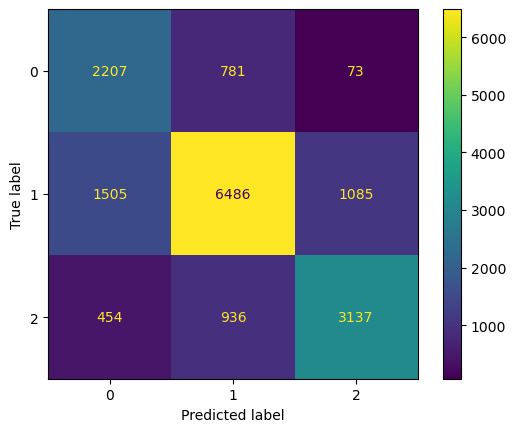

In [14]:
cm = confusion_matrix(y_test, y_pred)
dcm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels = modelo.classes_)
dcm.plot()

In [15]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.53      0.72      0.61      3061
           1       0.79      0.71      0.75      9076
           2       0.73      0.69      0.71      4527

    accuracy                           0.71     16664
   macro avg       0.68      0.71      0.69     16664
weighted avg       0.73      0.71      0.71     16664



**Prueba tú:** compara con `max_depth=5` y con `max_depth=10` dentro de `DecisionTreeClassifier(...)`. Un árbol sin límite memoriza el train y puede rendir peor en datos nuevos.

## 9. (Opcional) Comparar con KNN
KNN **sí** necesita escalado, porque mide distancias y una columna como `Outstanding_Debt` dominaría a `Interest_Rate`.
Fíjate: `fit_transform` solo en train y `transform` en test. El escalador debe aprender solo del train.
Si al final eliges KNN, tendrás que guardar también el escalador con `joblib.dump`.

In [16]:
escalado = StandardScaler()
X_train_escalado = escalado.fit_transform(X_train)
X_test_escalado = escalado.transform(X_test)

modelo_knn = KNeighborsClassifier(n_neighbors=5)
modelo_knn.fit(X_train_escalado, y_train)
y_pred_knn = modelo_knn.predict(X_test_escalado)
print('Accuracy KNN:', accuracy_score(y_test, y_pred_knn))
print('F1 KNN:', f1_score(y_test, y_pred_knn, average='weighted'))

Accuracy KNN: 0.6758881421027364
F1 KNN: 0.6766051418423287


## 10. Importancia de cada característica
Esto te sirve para la "justificación de la decisión" que pide el agente: qué columnas pesaron más en el modelo.

In [17]:
importancias = pd.Series(modelo.feature_importances_, index=X.columns).sort_values(ascending=False)
importancias

Outstanding_Debt            0.392201
Credit_Mix                  0.251351
Interest_Rate               0.142633
Delay_from_due_date         0.058601
Num_of_Delayed_Payment      0.057078
Monthly_Inhand_Salary       0.028806
Credit_History_Age          0.028051
Num_Credit_Inquiries        0.021827
Credit_Utilization_Ratio    0.010926
Payment_of_Min_Amount       0.008525
dtype: float64

## 11. Guardar el modelo (dump)
`joblib.dump` guarda el modelo ya entrenado en un archivo. La API lo abre con `joblib.load` y puede predecir sin reentrenar.

Guardamos también el **orden de las columnas**: el modelo solo conoce posiciones, no nombres. La API debe armar los datos en este mismo orden.

In [18]:
joblib.dump(modelo, 'modelo_riesgo.joblib')
joblib.dump(list(X.columns), 'columnas.joblib')

['columnas.joblib']

## 12. Comprobar que el archivo funciona


In [19]:
modelo_cargado = joblib.load('modelo_riesgo.joblib')
columnas_guardadas = joblib.load('columnas.joblib')

cliente = X_test[columnas_guardadas].iloc[[1]]
print('Predicción:', modelo_cargado.predict(cliente)[0], '| Real:', y_test.iloc[0])

Predicción: 2 | Real: 1
